# FELIX PySD Model Validation and Analysis

In [2]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import warnings

import pysd

import matplotlib.pyplot as plt



Matplotlib is building the font cache; this may take a moment.


## 1. Environment and paths

In [3]:
# Update these paths only if the project layout has changed.
MODEL_PATH = Path("output") / "FeliX3_ISE_v26_final_fixed.py"
HISTORICAL_FILE = Path("input") / "FeliX_HistoricalData.xlsx"


## 2. Load the model

In [4]:
# Load the generated default model.
t0 = time.time()
model = pysd.load(MODEL_PATH)

# Historical data describe the active labor force, not everyone of working age.
# Weight each gender/age slice by its participation rate before summing.
def patch_total_labor_force(mdl):
    def total_labor_force():
        people = mdl.components.labor_force()
        participation = mdl.components.labor_force_participation_fraction()
        return float((people * participation).sum().values)

    module = object.__getattribute__(mdl.components, "_components")
    # Replace the generated component only for this notebook session.
    setattr(module, "total_labor_force", total_labor_force)

patch_total_labor_force(model)

print(f"Model load time: {time.time() - t0:.1f}s")
print(f"PySD version: {pysd.__version__}")

# Display the model time settings.
print(f"\nInitial time: {model.components.initial_time()}")
print(f"Final time: {model.components.final_time()}")
print(f"Time step: {model.components.time_step()}")
print(f"Save interval: {model.components.saveper()}")

/Users/peter/codes/felix-pysd/.venv/lib/python3.12/site-packages/pysd/py_backend/lookups.py:108: UserWarning: _hardcodedlookup_lookup_for_the_impact_of_mys_on_climate_mortality
extrapolating data below the minimum value of the series
  warnings.warn(


Model load time: 14.9s
PySD version: 3.14.3

Initial time: 1900
Final time: 2100
Time step: 0.125
Save interval: 1


/Users/peter/codes/felix-pysd/.venv/lib/python3.12/site-packages/pysd/py_backend/lookups.py:108: UserWarning: _hardcodedlookup_effect_of_t_on_yield_lookup
extrapolating data below the minimum value of the series
  warnings.warn(


In [5]:
# Preview the model documentation table.
display(model.doc.head(10))

,Real Name,Py Name,Subscripts,Units,Limits,Type,Subtype,Comment
0,"""$ into $thousand""",nvs_into_thousand,None,Thousand,"(nan, nan)",Constant,Normal,NaN
1,"""(data) Agriculture Land per Billion Ha""",data_agriculture_land_per_billion_ha,None,Billion*ha,"(nan, nan)",Auxiliary,Normal,NaN
2,"""(data) Agriculture Land""",data_agriculture_land,None,ha,"(nan, nan)",Auxiliary,with Lookup,NaN
3,"""(data) DES for PoU FAOSTAT""",data_des_for_pou_faostat,None,kcal/(Person*Day),"(nan, nan)",Auxiliary,with Lookup,NaN
4,"""(data) Fat supply quantity from Animal Produc...",data_fat_supply_quantity_from_animal_products_fao,None,g/(Person*Day),"(nan, nan)",Auxiliary,with Lookup,NaN
5,"""(data) Fat supply quantity from Vegetal Produ...",data_fat_supply_quantity_from_vegetal_products...,None,g/(Person*Day),"(nan, nan)",Auxiliary,with Lookup,NaN
6,"""(data) Food supply quantity from Animal Produ...",data_food_supply_quantity_from_animal_products...,None,kcal/(Person*Day),"(nan, nan)",Auxiliary,with Lookup,NaN
7,"""(data) Food supply quantity from Vegetal Prod...",data_food_supply_quantity_from_vegetal_product...,None,kcal/(Person*Day),"(nan, nan)",Auxiliary,with Lookup,NaN
8,"""(data) Forest Land per Billion Ha""",data_forest_land_per_billion_ha,None,Billion*ha,"(nan, nan)",Auxiliary,Normal,NaN
9,"""(data) Forest Land""",data_forest_land,None,ha,"(nan, nan)",Auxiliary,with Lookup,NaN


## 3. Model structure and subscripts

FELIX uses many subscript dimensions, including age, gender, food categories, and energy types. Understanding these dimensions is essential for selecting slices from multidimensional variables.

In [6]:
# Method 1: inspect the legacy internal subscript dictionary.
# PySD 3.x exposes _subscript_dict through model.components.
_subscript_dict = model.components._subscript_dict

print(f"Subscript dimensions: {len(_subscript_dict)}\n")
print(f"{_subscript_dict}\n")

# Display two commonly used dimensions: gender and labor-force type.
for key in ["Gender", "Labor force type"]:
    vals = _subscript_dict[key]
    print(f"{key} ({len(vals)} elements):")
    # Print every coordinate value in the selected dimension.
    for v in vals:
        print(f"  - {v}")



Subscript dimensions: 51

{'Nutrients': ['Protein', 'Fat'], 'SupplyChain': ['Consumption', 'Distribution', 'Processing', 'PostHarvest', 'PrimaryProduction'], 'AllPlantButOther': ['Pulses', 'Grains', 'VegFruits'], 'AltProteins': ['AltPasMeat', 'AltCropMeat', 'AltDairy', 'AltEggs'], 'AltProteinTech': ['Plant', 'PrecFerm', 'Cult'], 'MapAltProteins': ['PasMeat', 'CropMeat', 'Dairy', 'Eggs'], 'PlantsPulsesVeg': ['Pulses', 'VegFruits'], 'MapAnimalFood': ['AltPasMeat', 'AltCropMeat', 'AltDairy', 'AltEggs'], 'YoGL cohorts': ['"20-24"', '"25-29"', '"30-34"', '"35-39"', '"40-44"', '"45-49"', '"50-54"', '"55-59"', '"60-64"', '"65-69"', '"70-74"', '"75-79"', '"80-84"', '"85-89"', '"90-94"', '"95-99"', '"100+"'], 'SchoolEnrollment': ['"5-9"', '"10-14"', '"15-19"', '"20-24"'], 'PrimaryEdButOldest': ['"10-14"', '"15-19"', '"20-24"', '"25-29"', '"30-34"', '"35-39"', '"40-44"', '"45-49"', '"50-54"', '"55-59"', '"60-64"', '"65-69"', '"70-74"', '"75-79"', '"80-84"', '"85-89"', '"90-94"', '"95-99"'], '"15

In [7]:
# Method 2: inspect subscripts through the current public API.
print(model.subscripts)

subscript_summary = pd.DataFrame([
    {
        "Subscript range": name,
        "Element count": len(values),
        "Preview": ", ".join(map(str, values[:6]))
        + (" …" if len(values) > 6 else ""),  # Preview only.
    }
    for name, values in model.subscripts.items()
]).sort_values(["Element count", "Subscript range"], ascending=[False, True])

print(f"Subscript ranges: {len(model.subscripts)}")
display(subscript_summary.reset_index(drop=True))

{'Nutrients': ['Protein', 'Fat'], 'SupplyChain': ['Consumption', 'Distribution', 'Processing', 'PostHarvest', 'PrimaryProduction'], 'AllPlantButOther': ['Pulses', 'Grains', 'VegFruits'], 'AltProteins': ['AltPasMeat', 'AltCropMeat', 'AltDairy', 'AltEggs'], 'AltProteinTech': ['Plant', 'PrecFerm', 'Cult'], 'MapAltProteins': ['PasMeat', 'CropMeat', 'Dairy', 'Eggs'], 'PlantsPulsesVeg': ['Pulses', 'VegFruits'], 'MapAnimalFood': ['AltPasMeat', 'AltCropMeat', 'AltDairy', 'AltEggs'], 'YoGL cohorts': ['"20-24"', '"25-29"', '"30-34"', '"35-39"', '"40-44"', '"45-49"', '"50-54"', '"55-59"', '"60-64"', '"65-69"', '"70-74"', '"75-79"', '"80-84"', '"85-89"', '"90-94"', '"95-99"', '"100+"'], 'SchoolEnrollment': ['"5-9"', '"10-14"', '"15-19"', '"20-24"'], 'PrimaryEdButOldest': ['"10-14"', '"15-19"', '"20-24"', '"25-29"', '"30-34"', '"35-39"', '"40-44"', '"45-49"', '"50-54"', '"55-59"', '"60-64"', '"65-69"', '"70-74"', '"75-79"', '"80-84"', '"85-89"', '"90-94"', '"95-99"'], '"15 to 24"': ['"15-19"', '"20

,Subscript range,Element count,Preview
0,Cohorts,21,"""0-4"", ""5-9"", ""10-14"", ""15-19"", ""20-24"", ""25-2..."
1,AllButOldest,20,"""0-4"", ""5-9"", ""10-14"", ""15-19"", ""20-24"", ""25-2..."
2,AllButYoungest,20,"""5-9"", ""10-14"", ""15-19"", ""20-24"", ""25-29"", ""30..."
3,NextCohort,20,"""5-9"", ""10-14"", ""15-19"", ""20-24"", ""25-29"", ""30..."
4,PreviousCohort,20,"""0-4"", ""5-9"", ""10-14"", ""15-19"", ""20-24"", ""25-2..."
5,PrimaryEdCohorts,19,"""10-14"", ""15-19"", ""20-24"", ""25-29"", ""30-34"", ""..."
6,MYS,18,"""15-19"", ""20-24"", ""25-29"", ""30-34"", ""35-39"", ""..."
7,PrimaryEdButOldest,18,"""10-14"", ""15-19"", ""20-24"", ""25-29"", ""30-34"", ""..."
8,SecondaryEdCohorts,18,"""15-19"", ""20-24"", ""25-29"", ""30-34"", ""35-39"", ""..."
9,PrimaryEdButYoungest,17,"""20-24"", ""25-29"", ""30-34"", ""35-39"", ""40-44"", ""..."


## 4. Quick execution test

In [8]:
# Run a quick simulation to verify that the translated model executes.
info = {
    "initial_time": model.time.initial_time(),
    "final_time":   model.time.final_time(),
    "time_step":    model.time.time_step(),
    "saveper":      model.time.saveper(),
    "current_time": model.time(),
}

print(info)

# Request core outputs and one two-dimensional cohort variable.
test_columns = [
    "Population", "Gross World Product", "Total Radiative Forcing", 
    "Total C Emissions", "Coal Production", "Wind Energy Production", 
    "Nonenergy Crops Production Indicator", "Forest Land", "population_cohorts"
]

# QUICK_FINAL_TIME = model.time.initial_time() + 50  # Example: 1972.
# print(QUICK_FINAL_TIME)

warnings.filterwarnings('ignore')  # Suppress repetitive model warnings.
t0 = time.time()
quick_result = model.run(
    # params={},  # Override model parameters for a scenario if needed.
    return_columns=test_columns,
    # final_time = QUICK_FINAL_TIME,
    time_step=1,
    # saveper=None,
)

print(f"\nQuick run completed in {time.time() - t0:.1f}s")
print(f"Result shape: {quick_result.shape}")
print(quick_result.head())


{'initial_time': 1900, 'final_time': 2100, 'time_step': 0.125, 'saveper': 1, 'current_time': 1900}

Quick run completed in 20.5s
Result shape: (201, 50)
        Population  Gross World Product  Total Radiative Forcing  \
time                                                               
1900  1.466458e+09         1.573135e+12                 0.293401   
1901  1.466870e+09         1.627053e+12                 0.293624   
1902  1.469151e+09         1.680900e+12                 0.303023   
1903  1.473477e+09         1.735398e+12                 0.308719   
1904  1.479544e+09         1.791274e+12                 0.315480   

      Total C Emissions  Coal Production  Wind Energy Production  \
time                                                               
1900       1.324230e+09       191.404648                0.000010   
1901       1.446305e+09       304.381743                0.001523   
1902       1.538487e+09       398.642395                0.002971   
1903       1.631209e+09       

## 5. Key variables

FELIX contains more than 2,000 variables. The table lists core analysis variables by module; request only the required items through `return_columns`.

| Module | Variable | Description |
|------|--------|------|
| **Population** | `population` | Total population |
| | `population_by_gender` | Population by gender |
| | `population_cohorts` | Population by age and gender |
| | `total_birth_rate` | Annual births |
| | `total_death_rate` | Annual deaths |
| | `total_fertility` | Total fertility rate |
| **Food system** | `food_supply_in_tonnes` | Food supply by category (tonnes/year) |
| | `food_supply_in_kcal` | Food supply by category (kcal/year) |
| | `caloric_availability_by_food_category` | Daily calories per capita |
| | `cropland_yield` | Cropland yield (tonnes/hectare/year) |
| | `production_rate_of_animal_food` | Animal-food production |
| **Energy and economy** | `gdp_per_capita_2000` | GDP per capita (2000 USD) |
| | `carbon_price` | Carbon price (USD/tCO2) |
| **GHG emissions** | `total_ghg_emissions_from_energy` | Energy-sector GHG emissions |
| | `total_ghg_emissions_from_afolu` | AFOLU GHG emissions |
| | `total_ghg_emissions_from_agriculture` | Agricultural GHG emissions |
| **Climate** | `global_mean_temperature_increase` | Global mean temperature increase (°C) |

## 6. Read subscript slices
PySD exposes model subscript definitions directly. The legacy `_subscript_dict` and current `model.subscripts` APIs are demonstrated above.
`return_columns` accepts Vensim-style slices. Age labels in this model retain their double quotes in xarray coordinates.
The following example reads and plots selected cohort slices.

<class 'pandas.DataFrame'>
Columns: ['population_cohorts[male,"0-4"]', 'population_cohorts[male,"5-9"]', 'population_cohorts[male,"10-14"]', 'population_cohorts[male,"15-19"]', 'population_cohorts[male,"20-24"]', 'population_cohorts[male,"25-29"]', 'population_cohorts[male,"30-34"]', 'population_cohorts[male,"35-39"]', 'population_cohorts[male,"40-44"]', 'population_cohorts[male,"45-49"]', 'population_cohorts[male,"50-54"]', 'population_cohorts[male,"55-59"]', 'population_cohorts[male,"60-64"]', 'population_cohorts[male,"65-69"]', 'population_cohorts[male,"70-74"]', 'population_cohorts[male,"75-79"]', 'population_cohorts[male,"80-84"]', 'population_cohorts[male,"85-89"]', 'population_cohorts[male,"90-94"]', 'population_cohorts[male,"95-99"]', 'population_cohorts[male,"100+"]', 'population_cohorts[female,"0-4"]', 'population_cohorts[female,"5-9"]', 'population_cohorts[female,"10-14"]', 'population_cohorts[female,"15-19"]', 'population_cohorts[female,"20-24"]', 'population_cohorts[female

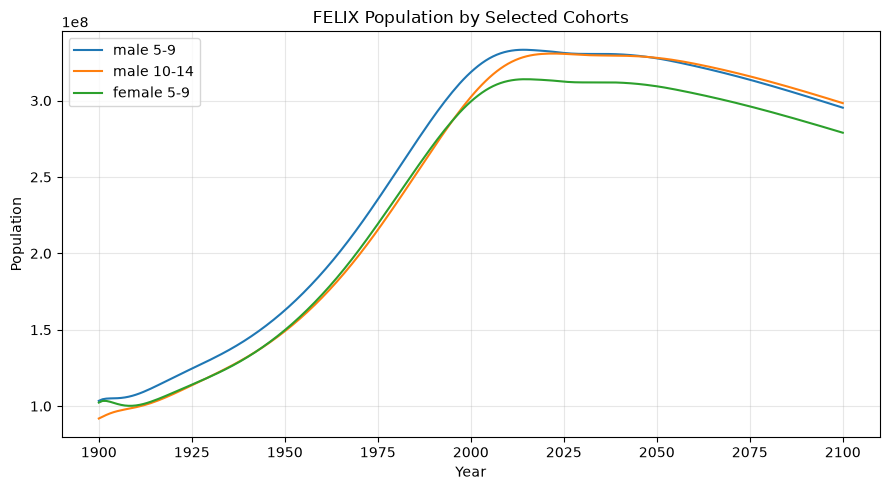

In [9]:
t0 = time.time()
# population_cohorts has dimensions Gender x Cohorts (2 x 21).

warnings.filterwarnings('ignore')  # Suppress repetitive model warnings.
cohorts_result = model.run(
    return_columns=["population_cohorts"],
    time_step=1,
)

print(type(cohorts_result))
print("Columns:", cohorts_result.columns.tolist())

# Select three representative cohort slices.
v1 = cohorts_result['population_cohorts[male,"5-9"]']
v2 = cohorts_result['population_cohorts[male,"10-14"]']
v3 = cohorts_result['population_cohorts[female,"5-9"]']

plt.figure(figsize=(9,5))
plt.plot(v1.index, v1.values, label='male 5-9')
plt.plot(v2.index, v2.values, label='male 10-14')
plt.plot(v3.index, v3.values, label='female 5-9')

plt.title("FELIX Population by Selected Cohorts")
plt.xlabel("Year")
plt.ylabel("Population")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Historical validation
This section follows the comparison context of Figure 8 in Ye et al. (2024), *FeliX 2.0: An integrated model of climate, economy, environment, and society interactions*.
It loads 15 historical indicators and runs the model through 2100 at annual output points for comparison.

In [10]:
# Load observations used for historical validation.
raw_history = pd.read_excel(HISTORICAL_FILE, sheet_name="Data", header=None)
history_years = pd.to_numeric(raw_history.iloc[0, 1:], errors="coerce")

# Extract and clean one historical series by its row label.
def history_series(row_name, end_year):
    """Return valid observations for one row through ``end_year``."""
    names = raw_history.iloc[:, 0].astype(str).str.strip()
    hits = raw_history.index[names.eq(row_name)]

    if len(hits) != 1:
        raise KeyError(f"Historical row {row_name!r} matched {len(hits)} times")
    # Convert blanks and nonnumeric cells to NaN.
    values = pd.to_numeric(raw_history.iloc[hits[0], 1:], errors="coerce")
    ok = history_years.notna() & values.notna() & (history_years <= end_year)
    
    out = pd.Series(values[ok].to_numpy(float), index=history_years[ok].to_numpy(int))
    out.index.name = "Year"
    return out.sort_index()

# ======================
# Map model outputs to historical series and display metadata.
# =======================
# Store each comparison as a compact specification dictionary.
VALIDATION_SPECS = [
    dict(key="Population", model="Population", history="Population", end=2020,
         scale=1e9, title="Population", unit="billion people", paper=.998),
    dict(key="Fertility", model="Total Fertility", history="Total Fertility", end=2020,
         scale=1, title="Total fertility rate", unit="births/woman", paper=.934),
    dict(key="Labor", model="Total Labor Force", history="Total Labor Force", end=2022,
         scale=1e9, title="Labor force", unit="billion people", paper=.997,
         note="Expected value is skill + unskill; rerun after changing the labor-force interpretation."),
    dict(key="Primary", model="Total Primary Education Graduates", history="Total Primary Education Graduates", end=2020,
         scale=1e9, title="Primary education graduates", unit="billion people", paper=.988),
    dict(key="Secondary", model="Total Secondary Education Graduates", history="Total Secondary Education Graduates", end=2020,
         scale=1e9, title="Secondary education graduates", unit="billion people", paper=.994),
    dict(key="Tertiary", model="Total Tertiary Education Graduates", history="Total Tertiary Education Graduates", end=2020,
         scale=1e9, title="Tertiary education graduates", unit="billion people", paper=.999),
    dict(key="GWP", model="Gross World Product", history="Gross World Product", end=2021,
         scale=1e12, title="Gross world product", unit="trillion $/yr", paper=.997),
    dict(key="GWPpc", model="GWP per Capita", history="GWP per Capita (in $)", end=2021,
         scale=1, title="GWP per capita", unit="$/person/yr", paper=.991),
    dict(key="Poverty", model="Global poverty rate", history="Global poverty rate", end=2022,
         scale=1, title="Global poverty rate", unit="%", paper=.988),
    dict(key="Energy", model="Energy Demand", history="Energy Demand", end=2022,
         scale=1e3, title="Energy demand", unit="Gtoe/yr", paper=.988),
    dict(key="AgrLand", model="Agricultural Land", history="Agricultural Land", end=2014,
         scale=1e9, title="Agricultural land", unit="billion ha", paper=.813),
    dict(key="CEmissions", model="Total C Emission from the Energy Sector", history="Total C Emission from Fossil Fuels", end=2019,
         scale=1e9, title="Energy-sector C emissions", unit="GtC/yr", paper=.985,
         note="The workbook series is fossil fuels; the model output also includes renewable carbon."),
    dict(key="Calories", model="Total Daily Calorie Supply per Capita", history="Total Daily Calorie Supply per Capita", end=2020,
         scale=1, title="Daily calorie supply", unit="kcal/person/day", paper=.973),
    dict(key="Temperature", model="Temperature Change from Preindustrial", history="Temperature Change from Preindustrial", end=2022,
         scale=1, title="Temperature change", unit="°C", paper=.982,
         note="The paper text reports 0.84, while Figure 8 labels 0.982."),
    dict(key="CO2", model="Atmospheric Concentration CO2", history="Atmospheric Concentration CO2", end=2016,
         scale=1, title="Atmospheric CO₂", unit="ppm", paper=.993),
]

# Additional outputs used by the comparison figures.
FIG9_OUTPUTS = [
    "Population", "Gross World Product", "Total Radiative Forcing", "Total C Emissions",
    "Coal Production", "Wind Energy Production", "Nonenergy Crops Production Indicator", "Forest Land",
]

# Load and scale every historical series defined above.
history = {s["key"]: history_series(s["history"], s["end"]) / s["scale"] for s in VALIDATION_SPECS}
HISTORICAL_OUTPUTS = list(dict.fromkeys(s["model"] for s in VALIDATION_SPECS))
REFERENCE_OUTPUTS = list(dict.fromkeys(HISTORICAL_OUTPUTS + FIG9_OUTPUTS))

print(REFERENCE_OUTPUTS)
print(len(REFERENCE_OUTPUTS))

['Population', 'Total Fertility', 'Total Labor Force', 'Total Primary Education Graduates', 'Total Secondary Education Graduates', 'Total Tertiary Education Graduates', 'Gross World Product', 'GWP per Capita', 'Global poverty rate', 'Energy Demand', 'Agricultural Land', 'Total C Emission from the Energy Sector', 'Total Daily Calorie Supply per Capita', 'Temperature Change from Preindustrial', 'Atmospheric Concentration CO2', 'Total Radiative Forcing', 'Total C Emissions', 'Coal Production', 'Wind Energy Production', 'Nonenergy Crops Production Indicator', 'Forest Land']
21


In [11]:
# Return annual points even when the integration time step is 0.125.
FINAL_YEAR = 2100
annual_years = np.arange(int(model.time.initial_time()), FINAL_YEAR + 1)

# Run the reference model independently.
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=UserWarning)
    reference_results = model.run(
        # params=scenario_params["SSP2 Reference + damage"],
        return_columns=REFERENCE_OUTPUTS,
        return_timestamps=annual_years,
        final_time=FINAL_YEAR,
        # time_step=SIM_TIME_STEP,  # Optional quick/full resolution switch.
        initial_condition="original",
        progress=False,
    )
    

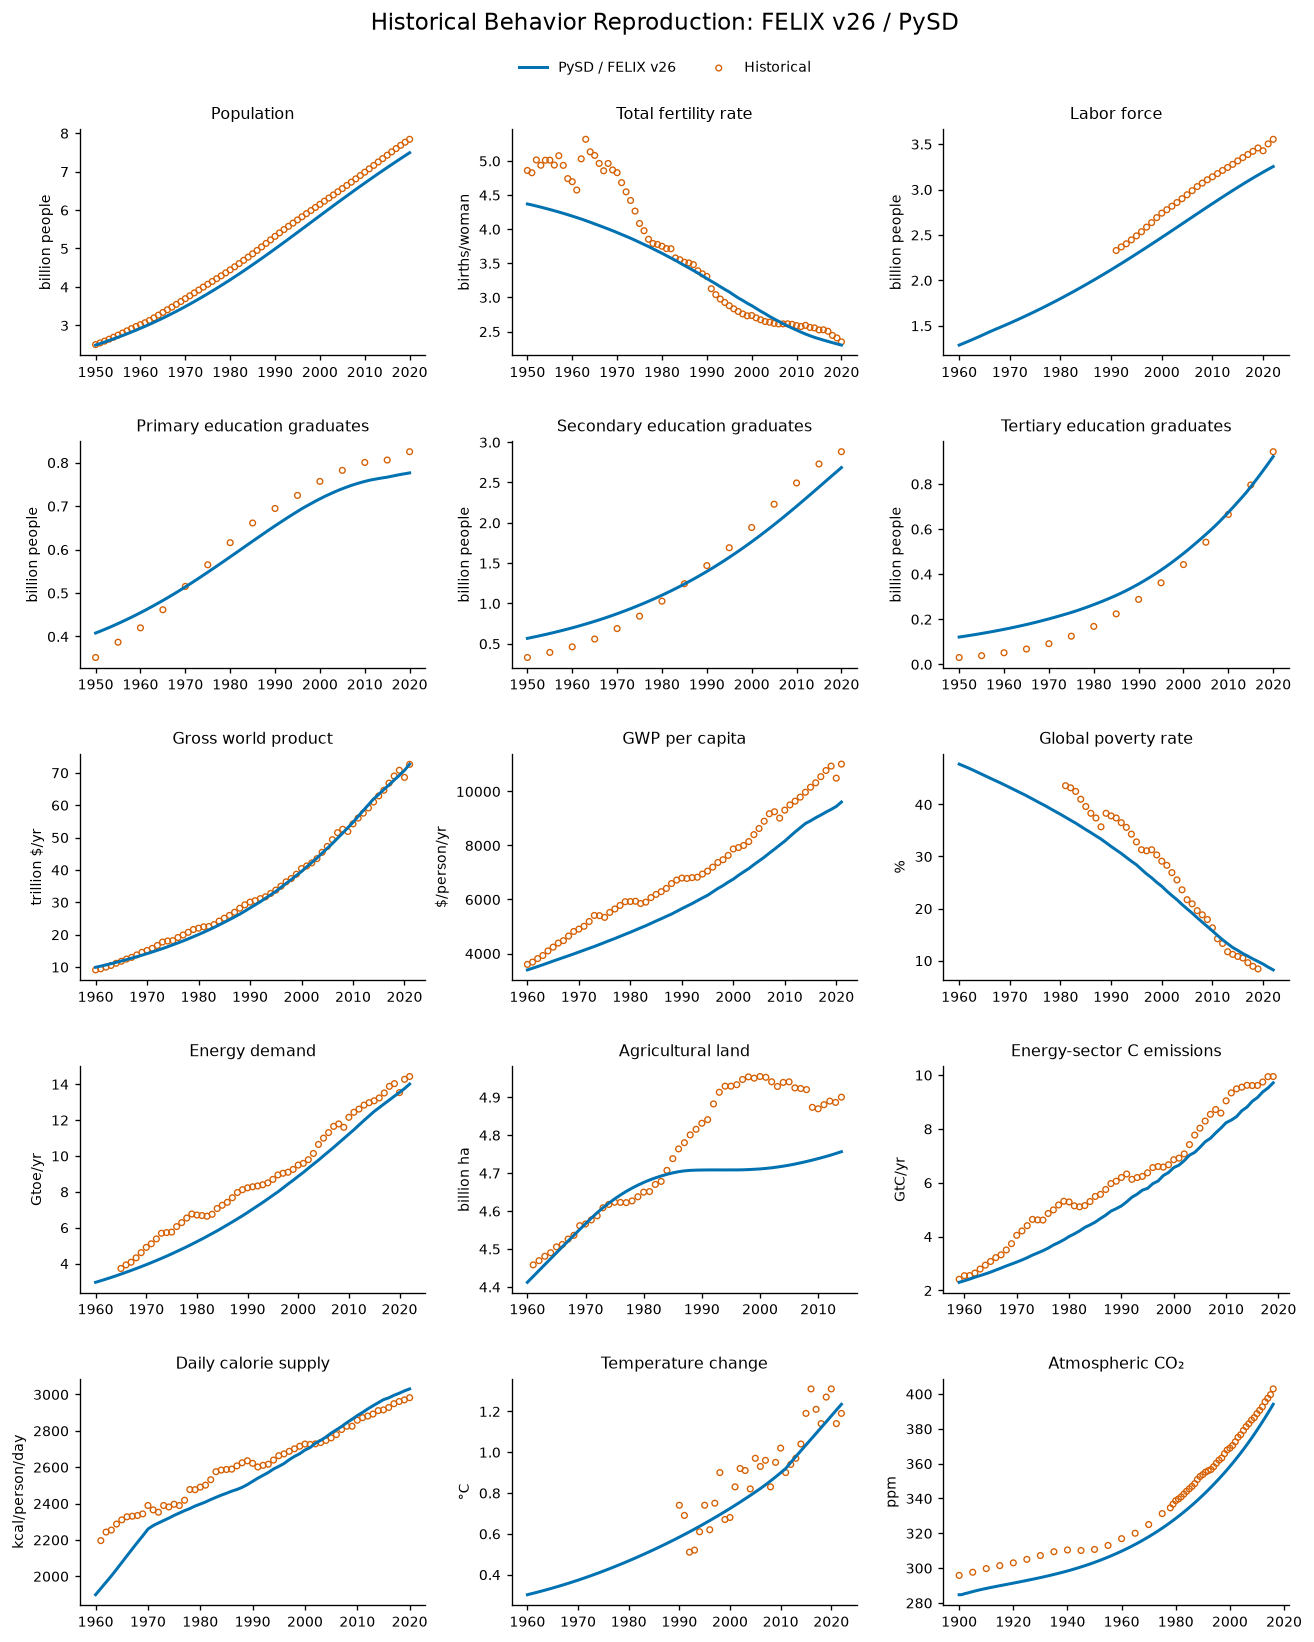

In [12]:
# ============================================================
# Compare historical observations with model simulations.
# Observation window: 1950-2020.
# ============================================================
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Configure publication-style plot defaults.
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "sans-serif", 
    "font.size": 8.5,
    "axes.titlesize": 9.5, 
    "axes.spines.top": False,
    "axes.spines.right": False, 
    "axes.grid": False,
    "figure.dpi": 120,
})

# Use the color-accessible Okabe-Ito palette.
OKABE_ITO = {"blue": "#0072B2", "red": "#D55E00", "gray": "#666666"}

# ------------------------------------------------------------
# 2. Prepare data and initialize the figure.
# ------------------------------------------------------------
# Reuse the complete reference run for historical comparisons.
historical_results = reference_results

# Create a 5 x 3 grid for the 15 validation indicators.
fig, axes = plt.subplots(5, 3, figsize=(13, 15))

# ------------------------------------------------------------
# 3. Plot every validation indicator.
# ------------------------------------------------------------
for ax, spec in zip(axes.flat, VALIDATION_SPECS): 
    # Load and scale the simulated and observed series.
    sim = historical_results[spec["model"]] / spec["scale"] 
    obs = history[spec["key"]]

    # Start no later than 1960 while retaining earlier observations.
    start = min(obs.index.min(), 1960) 
    
    # Plot the simulation as a line.
    sim.loc[start:spec["end"]].plot(
        ax=ax, 
        color=OKABE_ITO["blue"], 
        lw=1.8, 
        label="PySD / FELIX v26"
    )
    
    # Plot observations as open markers.
    ax.scatter(
        obs.index, obs.values, 
        s=12, marker="o", facecolors="none",
        edgecolors=OKABE_ITO["red"], linewidths=0.8, 
        label="Historical"
    )

    # Enable this annotation after metrics_table is available.
    # r2 = metrics_table.loc[spec["title"], "R²corr"] 
    # ax.text(0.03, 0.95, f"R²corr={r2:.3f}\nPaper={spec['paper']:.3f}", 
    #         transform=ax.transAxes, va="top", fontsize=8)
    
    # Format the current subplot.
    ax.set_title(spec["title"])
    ax.set_ylabel(spec["unit"])
    ax.set_xlabel("")
    ax.tick_params(direction="out", length=3)

# ------------------------------------------------------------
# 4. Configure the shared legend and title.
# ------------------------------------------------------------
# Reuse the first subplot's legend entries for the figure legend.
handles, labels = axes.flat[0].get_legend_handles_labels()

# Add the figure title.
fig.suptitle(
    "Historical Behavior Reproduction: FELIX v26 / PySD",
    fontsize=14, y=0.995,
)

# Center a frameless two-column legend above the subplots.
fig.legend(
    handles, labels, 
    loc="upper center", bbox_to_anchor=(0.5, 0.975), 
    ncol=2, frameon=False
)

# Adjust spacing to prevent overlapping labels.
fig.subplots_adjust(top=0.93, hspace=0.38, wspace=0.25)

plt.show()
